# **1) IMPLEMENTATION OF BB84 WITHOUT ANY NOISE**

In [ ]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime

In [ ]:
import random
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

In [ ]:
#SETUP PARAMETERS
n_qubits = 25      # number of qubits to send
test_fraction = 0.5  # fraction used to estimate error rate
with_eve = False     # set to False to simulate without eavesdropper

In [ ]:
#ALICE'S SIDE OF WORK

alice_bits = [random.randint(0, 1) for k in range(n_qubits)]
alice_bases = [random.randint(0, 1) for k in range(n_qubits)]

# Alice prepares her qubits
qr = QuantumRegister(n_qubits, "q")
cr = ClassicalRegister(n_qubits, "c")
alice_qc = QuantumCircuit(qr, cr)

for i in range(n_qubits):
    if alice_bits[i] == 1:
        alice_qc.x(qr[i])
    if alice_bases[i] == 1:
        alice_qc.h(qr[i])

In [ ]:
#eve intercept

if with_eve:
    eve_bases = [random.randint(0, 1) for _ in range(n_qubits)]
    sim = AerSimulator()

    qr_e = QuantumRegister(n_qubits, "q")
    cr_e = ClassicalRegister(n_qubits, "e")
    eve_qc = QuantumCircuit(qr_e, cr_e)
    eve_qc.compose(alice_qc, inplace=True)
    for i in range(n_qubits):
        if eve_bases[i] == 1:
            eve_qc.h(qr_e[i])
    eve_qc.measure(qr_e, cr_e)

    job = sim.run(transpile(eve_qc, sim), shots=1).result() # shots should be 1 for real life simulation
    counts = job.get_counts()
    bitstring = max(counts, key=counts.get)
    eve_bits = [int(b) for b in bitstring[::-1]]

    # Eve resends based on her measurements
    qr = QuantumRegister(n_qubits, "q")
    cr = ClassicalRegister(n_qubits, "c")
    alice_qc = QuantumCircuit(qr, cr)
    for i in range(n_qubits):
        if eve_bits[i] == 1:
            alice_qc.x(qr[i])
        if eve_bases[i] == 1:
            alice_qc.h(qr[i])

In [ ]:

#BOB MEASURES

bob_bases = [random.randint(0, 1) for _ in range(n_qubits)]

# Build circuit: Alice's encoded qubits + Bob's measurement
qr_bob = QuantumRegister(n_qubits, "q")
cr_bob = ClassicalRegister(n_qubits, "c")
bb84_qc = QuantumCircuit(qr_bob, cr_bob)
bb84_qc.compose(alice_qc, inplace=True)

for i in range(n_qubits):
    if bob_bases[i] == 1:
        bb84_qc.h(qr_bob[i])
bb84_qc.measure(qr_bob, cr_bob)

# Run on simulator
sim = AerSimulator()
t_qc = transpile(bb84_qc, sim)
job = sim.run(t_qc, shots=1) # shots should be 1 for real life simulation
result = job.result()
counts = result.get_counts()
bitstring = max(counts, key=counts.get)
bob_bits = [int(b) for b in bitstring[::-1]]



In [ ]:
#Sifting — keep bits where bases match

sift_a = []
sift_b = []
for i in range(n_qubits):
    if alice_bases[i] == bob_bases[i]:
        sift_a.append(alice_bits[i])
        sift_b.append(bob_bits[i])

if len(sift_a) == 0:
    print("No sifted bits. Try again with more qubits.")
else: # error estimation
    m = max(1, int(len(sift_a) * test_fraction))
    indices = random.sample(range(len(sift_a)), m)
    sample_a = [sift_a[i] for i in indices]
    sample_b = [sift_b[i] for i in indices]

    mismatches = sum(1 for x, y in zip(sample_a, sample_b) if x != y)
    error_rate_noiseless = mismatches / len(sample_a)

    remaining_indices = [i for i in range(len(sift_a)) if i not in indices]
    raw_key = [sift_a[i] for i in remaining_indices]


In [ ]:
print("=== BB84 run summary ===")
print("Total qubits sent:", n_qubits)
print("Sifted key length:", len(sift_a))
print("Sample size for error test:", m)
print("Estimated error rate: {:.2f}%".format(error_rate_noiseless * 100))
print("Raw key length:", len(raw_key))
print("Raw key:", "".join(str(b) for b in raw_key))
if error_rate_noiseless > 0.15:
    print("High error rate - Possible eavesdropping or noisy channel.")
else:
    print("Error rate acceptable. Shared key established.")


=== BB84 run summary ===
Total qubits sent: 25
Sifted key length: 13
Sample size for error test: 6
Estimated error rate: 16.67%
Raw key length: 7
Raw key: 0101010
High error rate - Possible eavesdropping or noisy channel.


# **IMPLEMENTATION OF BB84 WITHOUT ANY NOISE**

In [ ]:
import random
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
import matplotlib.pyplot as plt

In [ ]:
#SETUP
n_qubits = 25        # number of qubits to send
test_fraction = 0.5  # fraction used to estimate error rate
with_eve = False      # simulate eavesdropper or not

In [ ]:
#NOISY SIMULATION
backend = FakeSherbrooke()
noise_model = NoiseModel.from_backend(backend)
basis_gates = noise_model.basis_gates

# Create AerSimulator with noise
sim = AerSimulator(noise_model=noise_model, basis_gates=basis_gates)

In [ ]:
#ALICE DOING HER SIDE OF WORK
alice_bits = [random.randint(0, 1) for _ in range(n_qubits)]
alice_bases = [random.randint(0, 1) for _ in range(n_qubits)]

qr = QuantumRegister(n_qubits, "q")
cr = ClassicalRegister(n_qubits, "c")
alice_qc = QuantumCircuit(qr, cr)

for i in range(n_qubits):
    if alice_bits[i] == 1:
        alice_qc.x(qr[i])
    if alice_bases[i] == 1:
        alice_qc.h(qr[i])


In [ ]:
#EVE'S INTERCEPTION
if with_eve:
    eve_bases = [random.randint(0, 1) for _ in range(n_qubits)]

    qr_e = QuantumRegister(n_qubits, "q")
    cr_e = ClassicalRegister(n_qubits, "e")
    eve_qc = QuantumCircuit(qr_e, cr_e)
    eve_qc.compose(alice_qc, inplace=True)

    for i in range(n_qubits):
        if eve_bases[i] == 1:
            eve_qc.h(qr_e[i])
    eve_qc.measure(qr_e, cr_e)

    # Run Eve’s interception with noise
    job = sim.run(transpile(eve_qc, sim), shots=1)
    result = job.result()
    counts = result.get_counts()
    bitstring = max(counts, key=counts.get)
    eve_bits = [int(b) for b in bitstring[::-1]]

    # Eve resends what she measured
    qr = QuantumRegister(n_qubits, "q")
    cr = ClassicalRegister(n_qubits, "c")
    alice_qc = QuantumCircuit(qr, cr)
    for i in range(n_qubits):
        if eve_bits[i] == 1:
            alice_qc.x(qr[i])
        if eve_bases[i] == 1:
            alice_qc.h(qr[i])

In [ ]:
#BOB RECEIVING AND INTERPRETING ALICE'S SIGNAL
bob_bases = [random.randint(0, 1) for _ in range(n_qubits)]

qr_bob = QuantumRegister(n_qubits, "q")
cr_bob = ClassicalRegister(n_qubits, "c")
bb84_qc = QuantumCircuit(qr_bob, cr_bob)
bb84_qc.compose(alice_qc, inplace=True)

for i in range(n_qubits):
    if bob_bases[i] == 1:
        bb84_qc.h(qr_bob[i])
bb84_qc.measure(qr_bob, cr_bob)

# Run simulation with real noise model
t_qc = transpile(bb84_qc, sim)
job = sim.run(t_qc, shots=1)
result = job.result()
counts = result.get_counts()
bitstring = max(counts, key=counts.get)
bob_bits = [int(b) for b in bitstring[::-1]]


In [ ]:
#sifting and error checking
sift_a, sift_b = [], []
for i in range(n_qubits):
    if alice_bases[i] == bob_bases[i]:
        sift_a.append(alice_bits[i])
        sift_b.append(bob_bits[i])

if len(sift_a) == 0:
    print("No sifted bits. Try again with more qubits.")
else:

    m = max(1, int(len(sift_a) * test_fraction))
    indices = random.sample(range(len(sift_a)), m)
    sample_a = [sift_a[i] for i in indices]
    sample_b = [sift_b[i] for i in indices]

    mismatches = sum(1 for x, y in zip(sample_a, sample_b) if x != y)
    error_rate_noisy = mismatches / len(sample_a)

    remaining_indices = [i for i in range(len(sift_a)) if i not in indices]
    raw_key = [sift_a[i] for i in remaining_indices]


In [ ]:
print("BB84 with Realistic Noise")
print("Total qubits sent:", n_qubits)
print("Sifted key length:", len(sift_a))
print("Sample size for error test:", m)
print("Estimated error rate: {:.2f}%".format(error_rate_noisy * 100))
print("Raw key length:", len(raw_key))
print("Raw key:", "".join(str(b) for b in raw_key))
if error_rate_noisy > 0.15:
    print("High error rate — likely eavesdropping or quantum noise.")
else:
    print("Acceptable error rate. Shared key established.")


BB84 with Realistic Noise
Total qubits sent: 25
Sifted key length: 13
Sample size for error test: 6
Estimated error rate: 16.67%
Raw key length: 7
Raw key: 0100100
High error rate — likely eavesdropping or quantum noise.


# **PLOTTING PART**

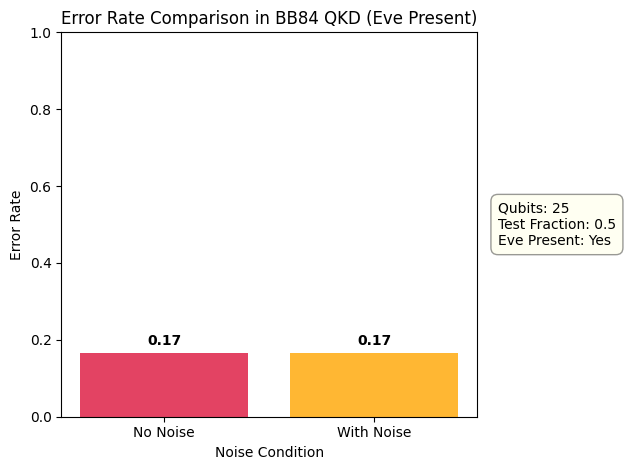

In [ ]:
labels = ['No Noise', 'With Noise']
values = [error_rate_noiseless, error_rate_noisy]

# Choose color scheme depending on Eve presence
if with_eve:
    colors = ['crimson', 'orange']
    title_suffix = " (Eve Present)"
else:
    colors = ['green', 'blue']
    title_suffix = " (No Eve)"

# Create the bar plot
plt.bar(labels, values, color=colors, alpha=0.8)

# Add titles and axis labels
plt.title(f'Error Rate Comparison in BB84 QKD{title_suffix}')
plt.xlabel('Noise Condition')
plt.ylabel('Error Rate')
plt.ylim(0, 1)

# Annotate bars with their values
for i, v in enumerate(values):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center', fontweight='bold')

# Add a text box with simulation info
info_text = (
    f'Qubits: {n_qubits}\n'
    f'Test Fraction: {test_fraction}\n'
    f'Eve Present: {"Yes" if with_eve else "No"}'
)
plt.text(1.05, 0.5, info_text, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='center',
         bbox=dict(facecolor='lightyellow', alpha=0.4, boxstyle='round,pad=0.5'))

# Improve layout
plt.tight_layout()
plt.show()